In [ ]:
#Unpicking the data
import pickle

with open("/content/images.p","rb") as f:
  images = pickle.load(f)

with open("/content/labels.p","rb") as f:
  labels = pickle.load(f)

In [ ]:
print(images.shape)
print(labels.shape)

(386, 100, 100)
(386,)


In [ ]:
set(labels)

{np.str_('Dharmapad'),
 np.str_('Himanshu'),
 np.str_('Rishu'),
 np.str_('jyotiprakash')}

In [ ]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

labels = le.fit_transform(labels)

In [ ]:
set(labels)

{np.int64(0), np.int64(1), np.int64(2), np.int64(3)}

In [ ]:
le.inverse_transform([0,1,2,3])

array(['Dharmapad', 'Himanshu', 'Rishu', 'jyotiprakash'], dtype='<U12')

In [ ]:
p = len(set(labels))
print("Total number of Persons : ",p)

Total number of Persons :  4


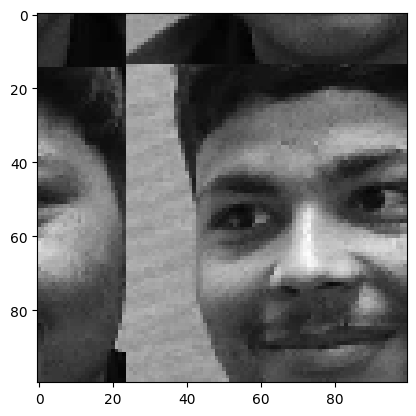

In [ ]:
import matplotlib.pyplot as plt
plt.imshow(images[195],cmap='gray')
plt.show()

In [ ]:
import cv2

In [ ]:
def preprocessing(img):
  img = cv2.equalizeHist(img)
  img = img.reshape(100,100,1)
  img = img/255
  return img

In [ ]:
import numpy as np

In [ ]:
images = np.array(list(map(preprocessing,images)))
print("Shape of Input : ",images.shape)

Shape of Input :  (386, 100, 100, 1)


In [ ]:
from keras.utils import to_categorical
labels = to_categorical(labels)

In [ ]:
from keras.models import Sequential
from keras.layers import Dense
from keras.optimizers import Adam

from keras.layers import Conv2D, MaxPooling2D, Flatten

In [ ]:
#Model Training
def Lenet_Model():
  model = Sequential()
  #Convolutional and ReLU Layer
  model.add(Conv2D(30,(5,5),input_shape=(100,100,1),activation='relu'))
  #MaxPooling Layer
  model.add(MaxPooling2D(pool_size=(2,2)))

  #Convolutional and ReLU Layer
  model.add(Conv2D(15,(3,3),activation='relu'))
  #MaxPooling Layer
  model.add(MaxPooling2D(pool_size=(2,2)))

  #Flatten Layer/Input Layer
  model.add(Flatten())

  #Hidden Layers
  model.add(Dense(50,activation='relu'))

  #Output Layer
  model.add(Dense(p,activation='softmax'))
  model.compile(Adam(learning_rate=0.01),loss='categorical_crossentropy',metrics=['accuracy'])
  return model


In [ ]:
model = Lenet_Model()
model.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 96, 96, 30)     │           780 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 48, 48, 30)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 46, 46, 15)     │         4,065 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 23, 23, 15)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 7935)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 50)             │       396,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           204 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 401,849 (1.53 MB)

 Trainable params: 401,849 (1.53 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
h = model.fit(images,labels,validation_split = 0.1,epochs=10)

Epoch 1/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 7s 470ms/step - accuracy: 0.3286 - loss: 3.3898 - val_accuracy: 0.0000e+00 - val_loss: 1.6497
Epoch 2/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 296ms/step - accuracy: 0.7733 - loss: 0.8340 - val_accuracy: 0.6667 - val_loss: 0.5891
Epoch 3/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 272ms/step - accuracy: 0.8193 - loss: 0.5298 - val_accuracy: 0.5897 - val_loss: 0.8590
Epoch 4/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 295ms/step - accuracy: 0.8803 - loss: 0.3601 - val_accuracy: 0.8462 - val_loss: 0.3771
Epoch 5/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 299ms/step - accuracy: 0.9278 - loss: 0.1774 - val_accuracy: 0.9744 - val_loss: 0.1671
Epoch 6/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 430ms/step - accuracy: 0.9854 - loss: 0.0864 - val_accuracy: 0.9744 - val_loss: 0.1463
Epoch 7/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 348ms/step - accuracy: 0.9571 - loss: 0.1037 - val_accuracy: 0.9744 - val_loss: 0.0822
Epoch 8/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 311ms/step - accuracy: 0.9807 - loss: 0.0594 - val_accuracy

In [ ]:
model.save('final_model.h5')